# 16 — All-terrace H/V panels and thickness estimates


## Imports and repository paths


In [1]:
from pathlib import Path
import sys

WORKING_DIR = Path.cwd().resolve()
ROOT = next((folder for folder in (WORKING_DIR, *WORKING_DIR.parents)
             if (folder / "utils/site_analysis.py").is_file()
             and (folder / "data/accelerometer").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or its processing folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display
from utils import hvsr_tools as hv
from utils import plotting as hp
from utils import site_analysis as sa


## Shared processing parameters


In [2]:
PARAMS = sa.BASE_PARAMS
FIGURE_DIR = ROOT / "main/02_hvsr_processing/figures/16_all_terraces"
DATA_DIR = ROOT / "main/02_hvsr_processing/data/16_all_terraces"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
display(pd.Series(PARAMS.to_dict(), name="Shared HVSR parameters"))


window_length_s                             120.0
overlap_pct                                   0.0
window_selection                       continuous
anti_trigger                                 True
sta_s                                         2.0
lta_s                                        30.0
sta_lta_min                                   0.1
sta_lta_max                                   2.0
sta_lta_components                      (N, E, Z)
sta_lta_amplitude                             abs
sta_lta_method                             vector
transient_padding_s                           2.0
max_crest_factor                             None
clip_threshold_pct                           None
filter_corners_hz                    (None, None)
filter_order                                    5
detrend                                    linear
orient_to_degrees_from_north                 None
taper_pct_per_side                            5.0
fft_zero_padding                            False


## Process the 15 terrace recordings


In [3]:
ANALYSES = sa.analyze_all_sites(ROOT, PARAMS)
SUMMARY = sa.site_summary(ANALYSES)
CURVES = sa.site_curves(ANALYSES)
display(SUMMARY.round(3))


,site_key,session_id,field_label,f0_hz,A0,reliability_count,clarity_count,n_windows,thickness_vs_150_m,thickness_vs_250_m,thickness_vs_350_m
0,01_terrace_28,CBUCF_titanSMA_1614_20230519_213500_02,Terraza 28,10.777,1.194,3,2,5,3.480,5.800,8.119
1,02_terrace_27,CBUCF_titanSMA_1614_20230519_221100_01,Terraza 27,15.121,1.098,3,3,8,2.480,4.133,5.787
2,03_terrace_32,CBUCF_titanSMA_1614_20230519_224800_01,Terraza 32,38.716,1.931,3,3,10,0.969,1.614,2.260
3,04_unnumbered_terrace_opposite_frog,CBUCF_titanSMA_1614_20230519_232900_01,Terraza sin número frente a la rana,1.836,0.721,3,3,9,20.422,34.037,47.652
4,05_terrace_39e,CBUCF_titanSMA_1614_20230520_103800_02,Terraza 39E (abajo helipuerto),11.468,0.810,3,2,8,3.270,5.450,7.630
5,06_terrace_40e,CBUCF_titanSMA_1614_20230520_110900_01,Terraza 40E,2.576,0.934,3,3,9,14.555,24.258,33.961
6,07_terrace_41e,CBUCF_titanSMA_1614_20230520_113700_01,Terraza 41E,14.608,1.025,3,4,8,2.567,4.279,5.990
7,08_terrace_44,CBUCF_titanSMA_1614_20230520_120239_02,Terraza 44,23.699,1.359,3,3,8,1.582,2.637,3.692
8,09_terrace_46,CBUCF_titanSMA_1614_20230520_123500_02,Terraza 46,18.865,1.406,3,4,7,1.988,3.313,4.638
9,10_east_of_terrace_74_wall_crown,CBUCF_titanSMA_1614_20230520_200700_03,"Exterior al este de Terraza 74, corona muro ba...",16.092,1.104,3,1,11,2.330,3.884,5.437


## Export summary and spectral data


In [4]:
SUMMARY.to_csv(DATA_DIR / "all_terraces_summary.csv", index=False)
CURVES.to_csv(DATA_DIR / "all_terraces_mean_curves.csv", index=False)
display({"summary": DATA_DIR / "all_terraces_summary.csv",
         "curves": DATA_DIR / "all_terraces_mean_curves.csv"})


{'summary': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/16_all_terraces/all_terraces_summary.csv'),
 'curves': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/16_all_terraces/all_terraces_mean_curves.csv')}

## Generate the 15-panel H/V figure


{'pdf': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/16_all_terraces/all_terraces_hvsr_panels.pdf'),
 'svg': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/16_all_terraces/all_terraces_hvsr_panels.svg'),
 'png': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/16_all_terraces/all_terraces_hvsr_panels.png')}

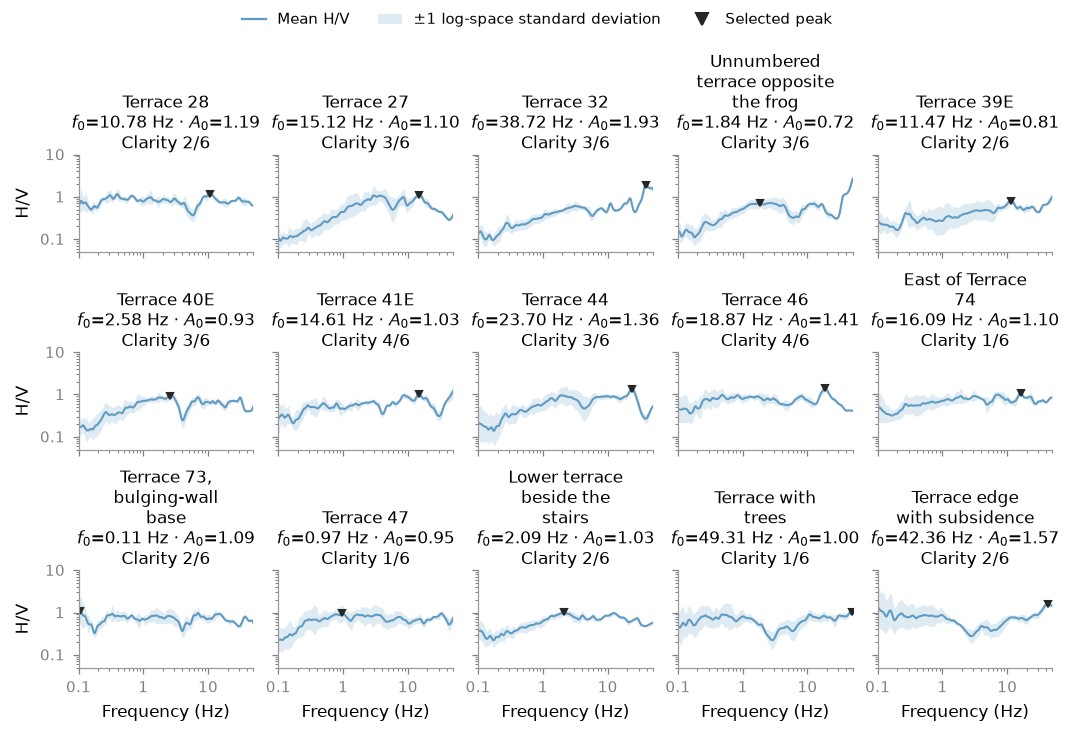

In [5]:
STYLE = hp.PaperStyle(width_in=7.0, font_size=8.0, tick_size=7.0,
                        legend_size=7.0, dpi=300)
PANEL_FIGURE = sa.plot_site_panels(ANALYSES, style=STYLE)
PANEL_PATHS = hp.save_figure(
    PANEL_FIGURE, FIGURE_DIR / "all_terraces_hvsr_panels",
    formats=("pdf", "svg", "png"), style=STYLE,
)
display(PANEL_PATHS)


## Generate the thickness-sensitivity figure


In [6]:
THICKNESS_FIGURE = sa.plot_thickness_summary(ANALYSES, style=STYLE)
THICKNESS_PATHS = hp.save_figure(
    THICKNESS_FIGURE, FIGURE_DIR / "all_terraces_f0_thickness",
    formats=("pdf", "svg", "png"), style=STYLE,
)
display(THICKNESS_PATHS)


{'pdf': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/16_all_terraces/all_terraces_f0_thickness.pdf'),
 'svg': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/16_all_terraces/all_terraces_f0_thickness.svg'),
 'png': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/16_all_terraces/all_terraces_f0_thickness.png')}